# v8 — **Completing the four pillars**
**US · Eurozone · UK · Switzerland · Japan** — one researched, robust signal for each of Macro, Micro, Valuation and Technical

## Where this picks up
Macro and Micro are settled by v4–v7. **Valuation and Technical are the open work**, and valuation has failed in every form tried so far. This notebook diagnoses *why* and builds candidates that attack the diagnosed cause.

### The diagnosed failure of valuation
From the return identity $\Delta\log P = \Delta\log EPS + \Delta\log(P/E)$, v5 and v7 established:

| Valuation signal (cheap = high) | multiple leg | earnings leg | total |
|---|---|---|---|
| P/E vs own history | **+0.149 / +0.097** | +0.041 / **−0.215** | +0.077 / −0.017 |
| P/E vs peers | +0.077 / +0.098 | +0.089 / −0.267 | +0.076 / −0.050 |

**Cheap markets do re-rate upward — and simultaneously have their earnings estimates cut. The two legs cancel.**
Raw P/E selects for *cheap-for-a-reason*. v5 also showed the obvious fix fails: multiplying cheapness by earnings stability **destroys** the information (+0.130 → +0.009), because a product of z-scores is large when *both* components are low.

So a valuation signal can only work if it either **(a)** removes the earnings-deterioration component, or **(b)** measures cheapness against a benchmark that already prices the risk causing the cheapness.

## Candidates — directions fixed ex ante, none added later
### Valuation (6)
| ID | Signal | Mechanism | Attacks |
|---|---|---|---|
| **V1** | Equity–credit premium gap: $z(E/P - y_{2} - OAS)$ | Equity and credit are claims on the *same* cash flows. A wide equity excess yield **relative to the market's own credit spread** means equity is cheap after the market's assessment of corporate risk | (b) |
| **V2** | Earnings-residualised cheapness: cross-sectional residual of $z(\text{cheap})$ on $z(\text{EPS rev 6M})$ | "Cheap for reasons *other than* deteriorating earnings" — subtracts rather than multiplies | (a) |
| **V3** | Multiple reversal: $-z(\Delta\log P/E_{6M})$ | Multiples that compressed tend to bounce; a *change* measure cannot select for chronic cheapness | (a) |
| **V4** | ERP momentum: $\Delta_{6M}(E/P - y_2)$ | Equity risk premium *widening* = getting cheaper vs the local risk-free alternative | (b) |
| **V5** | Growth-neutral relative value: $z(-\text{rel }P/E) - z(\text{rel EPS growth 12M})$ | Additive neutralisation of the "cheap because shrinking" component | (a) |
| **V6** | Extremity-gated cheapness: $z(\text{cheap})$ only where $|z_{own}(P/E)|>1$, else neutral | Mean reversion is only reliable from extremes; avoids taking a view mid-range | (a) |

### Technical (6)
| ID | Signal | Mechanism |
|---|---|---|
| **T1** | Momentum 12-1M | Academic standard; trend persistence, skip the reversal month |
| **T2** | Intermediate momentum 12-7M | The "echo": older momentum is more robust than recent |
| **T3** | Earnings-confirmed momentum (gated, not multiplied) | Trend counts only where 12M EPS growth is also positive |
| **T4** | Trend consistency: share of last 12M with positive *relative* return | Steady trends persist; jumpy ones do not. Measures path, not size |
| **T5** | Risk-adjusted momentum 12-1M / realised vol | Trend per unit of risk |
| **T6** | Proximity to 12M high | Strength near highs; anchoring/underreaction |

## Selection rule — fixed before any result
A candidate qualifies only if **all three** hold:
1. IC positive in **both** discovery (2007-16) **and** validation (2017-26) on the primary target (relative USD 3M);
2. positive in **≥4 of the 6** non-overlapping 6M offsets (v7 proved single-offset results are unreliable);
3. **economically coherent leg attribution** — a valuation signal must predict the **multiple leg** positively (that is what valuation *is*); a technical signal may work through either leg.

Among qualifiers, take the highest **mean of discovery and validation IC** — never the max of either. If none qualifies, the pillar is reported as **failed**, documented, and given zero weight; no signal is manufactured.
Finally the winner is checked against a **max-statistic null over all 12 candidates**, so the pillar winner is not simply the best of twelve noise draws.

## ⚠ Standing caveat
The 2017-26 window has now been examined in v3–v7. This is **not** a clean hold-out; it is a structured re-use with a declared rule and a multiplicity correction. Price return only, no dividends.

## 0. Setup and data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 230
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v8'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
DISC = (pd.Period('2007-01', 'M'), pd.Period('2016-12', 'M')); VALW = (pd.Period('2017-07', 'M'), pd.Period('2026-04', 'M'))
SEED = 7
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(s):
    d = monthly(pd.read_excel(ROOT/'data'/'raw'/s['file']))
    o = pd.DataFrame({'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'y2': d[s['y2']], 'oas': d[s['oas']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(SPEC[c]) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, Y2, OAS, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'y2', 'oas', 'fci', 'fx')]
AS_OF = IDX[-1]; PX = PE * EPS; PX_USD = PX * FX; R_USD = PX_USD.pct_change()
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
own_sd = lambda d, w=36: d / d.expanding(w).std()
TGT = {}
for h in (3, 6):
    tot = PX_USD.shift(-h) / PX_USD - 1
    TGT[('total', h)] = tot.sub(tot.mean(axis=1), axis=0)
    for nm, ser in (('multiple', np.log(PE.shift(-h) / PE)), ('earnings', np.log(EPS.shift(-h) / EPS))):
        TGT[(nm, h)] = ser.sub(ser.mean(axis=1), axis=0)
print(f'Panel {IDX[0]} -> {AS_OF} ({len(IDX)} months). Price = fwd P/E x fwd EPS (identity, verified v4 §12b).')

Panel 2005-12 -> 2026-04 (245 months). Price = fwd P/E x fwd EPS (identity, verified v4 §12b).


## 1. Building the candidates
Every construction below was specified in §0 before being run. The two settled pillars are carried forward unchanged.

In [2]:
EPSREV6 = EPS / EPS.shift(6) - 1
EPSG12 = EPS / EPS.shift(12) - 1
EPSSTAB = -EPS.pct_change().rolling(12).std()
EYLD = 100 / PE                                   # earnings yield, %
ERP = EYLD - Y2                                   # equity risk premium vs local 2Y
CHEAP_OWN = -z_own(PE)                            # cheap vs own history
CHEAP_REL = -z_own(PE.div(PE.mean(axis=1), axis=0))
RELRET = R_USD.sub(R_USD.mean(axis=1), axis=0)

def xs_residual(y_df, x_df):
    """cross-sectional residual of y on x, month by month (5 obs, 1 regressor)"""
    out = pd.DataFrame(index=y_df.index, columns=COUNTRIES, dtype=float)
    for t in y_df.index:
        y, x = y_df.loc[t], x_df.loc[t]
        if y.notna().all() and x.notna().all() and x.std() > 0:
            b = np.polyfit(x.values, y.values, 1); out.loc[t] = y.values - np.polyval(b, x.values)
    return out

VAL_CAND = {
 'V1 equity-credit premium gap':      z_own(ERP - OAS),
 'V2 earnings-residualised cheapness': xs_residual(cs_z(CHEAP_REL), cs_z(EPSREV6)),
 'V3 multiple reversal (6M)':         -own_sd(np.log(PE / PE.shift(6))),
 'V4 ERP momentum (6M)':               own_sd(ERP - ERP.shift(6)),
 'V5 growth-neutral relative value':   cs_z(CHEAP_REL) - cs_z(EPSG12),
 'V6 extremity-gated cheapness':       CHEAP_OWN.where(z_own(PE).abs() > 1, 0.0),
}
TECH_CAND = {
 'T1 momentum 12-1M':        PX.shift(1) / PX.shift(13) - 1,
 'T2 intermediate mom 12-7M': PX.shift(7) / PX.shift(13) - 1,
 'T3 earnings-confirmed mom': (PX.shift(1) / PX.shift(13) - 1).where(EPSG12 > 0, 0.0),
 'T4 trend consistency 12M':  (RELRET > 0).rolling(12).mean() - 0.5,
 'T5 risk-adjusted mom 12-1M': (PX.shift(1) / PX.shift(13) - 1) / R_USD.rolling(12).std(),
 'T6 proximity to 12M high':   PX / PX.rolling(12).max() - 1,
}
SETTLED = {'MACRO fci easing 6M': own_sd(FCI - FCI.shift(6)),
           'MICRO eps revision 6M': EPSREV6,
           'MICRO eps stability 12M': EPSSTAB}
CAND = {**VAL_CAND, **TECH_CAND}
Z = {k: cs_z(v.reindex(IDX)) for k, v in {**CAND, **SETTLED}.items()}
print(f'{len(VAL_CAND)} valuation + {len(TECH_CAND)} technical candidates + {len(SETTLED)} settled signals built.')
print('First month all candidates valid:', max(z.dropna().index.min() for z in Z.values()))

6 valuation + 6 technical candidates + 3 settled signals built.
First month all candidates valid: 2010-11


## 2. Evaluation machinery

In [3]:
def ic_series(sig, tgt):
    o = {}
    for t in sig.index:
        a, b = sig.loc[t], tgt.loc[t]
        if a.notna().all() and b.notna().all() and a.nunique() > 1: o[t] = spearmanr(a, b).statistic
    return pd.Series(o)
def win(s, w): return s[(s.index >= w[0]) & (s.index <= w[1])]
def nw_t(x, lags=3):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 8 else np.nan
def evaluate(name, sig):
    r = {'candidate': name}
    ic3 = ic_series(sig, TGT[('total', 3)])
    r['disc IC'] = win(ic3, DISC).mean(); r['disc t'] = nw_t(win(ic3, DISC).values)
    r['val IC'] = win(ic3, VALW).mean(); r['val t'] = nw_t(win(ic3, VALW).values)
    r['mean IC'] = (r['disc IC'] + r['val IC']) / 2
    ic6 = ic_series(sig, TGT[('total', 6)])
    offs = [ic6.iloc[o::6].mean() for o in range(6)]
    r['offsets +'] = int(sum(v > 0 for v in offs)); r['offset mean'] = float(np.mean(offs))
    r['leg multiple'] = ic_series(sig, TGT[('multiple', 3)]).mean()
    r['leg earnings'] = ic_series(sig, TGT[('earnings', 3)]).mean()
    r['_offs'] = offs
    return r
ALL = pd.DataFrame([evaluate(k, Z[k]) for k in {**CAND, **SETTLED}]).set_index('candidate')
OFFS = ALL.pop('_offs')
fmt = {c: '{:+.3f}' for c in ALL.columns if 'IC' in c or 'leg' in c} | {c: '{:+.2f}' for c in ALL.columns if c.endswith(' t')}
print('VALUATION candidates'); display(ALL.loc[list(VAL_CAND)].style.format(fmt))
print('TECHNICAL candidates'); display(ALL.loc[list(TECH_CAND)].style.format(fmt))
print('SETTLED pillars (carried forward)'); display(ALL.loc[list(SETTLED)].style.format(fmt))

VALUATION candidates


,disc IC,disc t,val IC,val t,mean IC,offsets +,offset mean,leg multiple,leg earnings
candidate,,,,,,,,,
V1 equity-credit premium gap,+0.100,+1.15,-0.017,-0.25,+0.041,6,0.113333,+0.132,-0.131
V2 earnings-residualised cheapness,+0.109,+1.64,-0.089,-1.52,+0.010,5,0.016111,+0.083,-0.093
V3 multiple reversal (6M),+0.093,+1.75,+0.059,+1.03,+0.076,4,0.044949,+0.112,-0.048
V4 ERP momentum (6M),+0.127,+1.87,-0.019,-0.29,+0.054,4,0.055051,+0.052,-0.030
V5 growth-neutral relative value,+0.058,+0.88,-0.127,-1.90,-0.035,1,-0.037778,+0.127,-0.238
V6 extremity-gated cheapness,+0.158,+2.08,-0.135,-1.76,+0.012,3,0.000052,+0.043,-0.079


TECHNICAL candidates


,disc IC,disc t,val IC,val t,mean IC,offsets +,offset mean,leg multiple,leg earnings
candidate,,,,,,,,,
T1 momentum 12-1M,+0.055,+1.06,+0.103,+1.38,+0.079,6,0.085680,-0.080,+0.234
T2 intermediate mom 12-7M,+0.055,+0.97,+0.046,+0.72,+0.050,6,0.067520,-0.012,+0.058
T3 earnings-confirmed mom,+0.097,+1.52,+0.113,+1.50,+0.105,6,0.140489,-0.053,+0.246
T4 trend consistency 12M,-0.048,-0.62,-0.054,-0.80,-0.051,3,-0.006354,-0.113,+0.051
T5 risk-adjusted mom 12-1M,+0.061,+0.98,+0.135,+1.82,+0.098,6,0.126920,-0.030,+0.224
T6 proximity to 12M high,+0.022,+0.43,+0.057,+0.85,+0.040,5,0.038370,-0.148,+0.233


SETTLED pillars (carried forward)


,disc IC,disc t,val IC,val t,mean IC,offsets +,offset mean,leg multiple,leg earnings
candidate,,,,,,,,,
MACRO fci easing 6M,+0.079,+1.08,+0.127,+1.74,+0.103,6,0.174242,-0.069,+0.213
MICRO eps revision 6M,+0.117,+1.67,+0.131,+1.70,+0.124,6,0.130353,-0.089,+0.333
MICRO eps stability 12M,+0.079,+1.38,+0.146,+2.12,+0.112,6,0.126683,+0.103,+0.046


## 3. Applying the pre-declared selection rule

In [4]:
def qualifies(nm, pillar):
    r = ALL.loc[nm]
    c1 = r['disc IC'] > 0 and r['val IC'] > 0
    c2 = r['offsets +'] >= 4
    c3 = (r['leg multiple'] > 0) if pillar == 'Valuation' else True
    return c1, c2, c3, (c1 and c2 and c3)
rows = []
for nm in VAL_CAND: 
    c1, c2, c3, ok = qualifies(nm, 'Valuation'); rows.append({'pillar': 'Valuation', 'candidate': nm, '1 both windows +': c1, '2 >=4/6 offsets': c2, '3 predicts multiple leg': c3, 'QUALIFIES': ok, 'mean IC': ALL.loc[nm, 'mean IC']})
for nm in TECH_CAND:
    c1, c2, c3, ok = qualifies(nm, 'Technical'); rows.append({'pillar': 'Technical', 'candidate': nm, '1 both windows +': c1, '2 >=4/6 offsets': c2, '3 predicts multiple leg': 'n/a', 'QUALIFIES': ok, 'mean IC': ALL.loc[nm, 'mean IC']})
QUAL = pd.DataFrame(rows).set_index(['pillar', 'candidate'])
display(QUAL.style.format({'mean IC': '{:+.3f}'}))
WINNERS = {}
for pillar, pool in (('Valuation', VAL_CAND), ('Technical', TECH_CAND)):
    q = [nm for nm in pool if qualifies(nm, pillar)[3]]
    if q:
        best = max(q, key=lambda n: ALL.loc[n, 'mean IC']); WINNERS[pillar] = best
        print(f'{pillar:10s}: {len(q)} qualify -> WINNER "{best}" (mean IC {ALL.loc[best,"mean IC"]:+.3f})')
    else:
        WINNERS[pillar] = None
        best_fail = max(pool, key=lambda n: ALL.loc[n, 'mean IC'])
        print(f'{pillar:10s}: 0 qualify -> PILLAR FAILS. Best non-qualifier "{best_fail}" (mean IC {ALL.loc[best_fail,"mean IC"]:+.3f})')

Valuation : 1 qualify -> WINNER "V3 multiple reversal (6M)" (mean IC +0.076)
Technical : 5 qualify -> WINNER "T3 earnings-confirmed mom" (mean IC +0.105)


## 4. Multiplicity check — is the pillar winner just the best of twelve?
Twelve candidates were screened. Country labels are block-shuffled (3-month blocks, the same permutation applied to every candidate so their correlation is preserved) and the **maximum mean-IC across all twelve** is recorded. 2,000 replications.

Best observed among the 12 candidates : +0.098 (T3 earnings-confirmed mom)
Best-of-12 NULL                       : median +0.065, 95th pct +0.120, max +0.197


,winner,full-sample IC,p vs best-of-12 null
pillar,,,
Valuation,V3 multiple reversal (6M),+0.080,0.321
Technical,T3 earnings-confirmed mom,+0.098,0.144


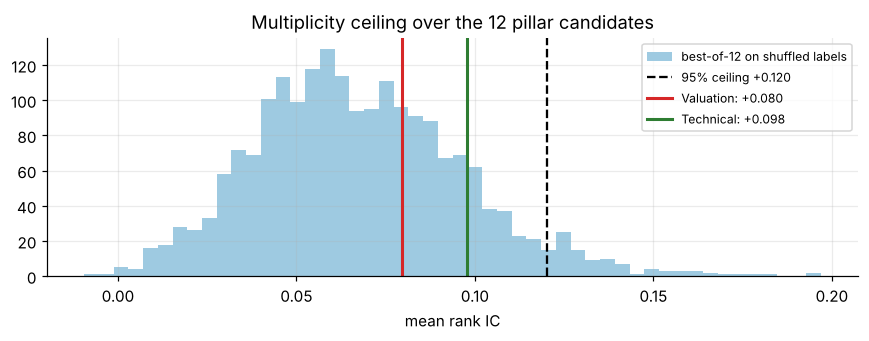

In [5]:
rng = np.random.default_rng(SEED); NREP = 2000
cand_names = list(CAND)
from scipy.stats import rankdata
A = np.stack([Z[n].to_numpy(float) for n in cand_names])               # (12,T,5)
Ttot = A.shape[1]; blk = np.arange(Ttot) // 3
Yt = TGT[('total', 3)].to_numpy(float)
# Permuting country labels permutes the RANKS identically, so rank once and the null becomes one einsum.
def centred_ranks(M):
    out = np.full(M.shape, np.nan)
    good = ~np.isnan(M).any(axis=-1)
    out[good] = rankdata(M[good], axis=-1) - 3.0
    return out
SR = centred_ranks(A)                                                   # (12,T,5)
FR = centred_ranks(Yt)                                                  # (T,5)
okS = ~np.isnan(SR).any(-1); okF = ~np.isnan(FR).any(-1)
SRz, FRz = np.nan_to_num(SR), np.nan_to_num(FR)
den = np.sqrt((SRz**2).sum(-1) * (FRz**2).sum(-1)[None, :]); den[den == 0] = np.nan
VAL_MASK = okS & okF[None, :] & ~np.isnan(den)
def mean_ic_from(SRarr):
    ic = np.einsum('itc,tc->it', SRarr, FRz) / den
    return np.nanmean(np.where(VAL_MASK, ic, np.nan), axis=1)
obs_all = mean_ic_from(SRz)
nullmax = np.empty(NREP)
for r in range(NREP):
    perm = np.argsort(rng.random((blk.max() + 1, 5)), axis=1)[blk]      # (T,5), same shuffle for all candidates
    nullmax[r] = np.nanmax(mean_ic_from(np.take_along_axis(SRz, perm[None, :, :], axis=2)))
ceil95 = np.percentile(nullmax, 95)
print(f'Best observed among the 12 candidates : {np.nanmax(obs_all):+.3f} ({cand_names[int(np.nanargmax(obs_all))]})')
print(f'Best-of-12 NULL                       : median {np.median(nullmax):+.3f}, 95th pct {ceil95:+.3f}, max {nullmax.max():+.3f}')
rows = []
for pillar, nm in WINNERS.items():
    if nm is None: continue
    o = obs_all[cand_names.index(nm)]
    rows.append({'pillar': pillar, 'winner': nm, 'full-sample IC': o, 'p vs best-of-12 null': float((nullmax >= o).mean())})
if rows: display(pd.DataFrame(rows).set_index('pillar').style.format({'full-sample IC': '{:+.3f}', 'p vs best-of-12 null': '{:.3f}'}))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(nullmax, bins=50, color='#9ecae1', label='best-of-12 on shuffled labels')
ax.axvline(ceil95, color='k', ls='--', label=f'95% ceiling {ceil95:+.3f}')
for pillar, nm in WINNERS.items():
    if nm: ax.axvline(obs_all[cand_names.index(nm)], lw=2, color='#d62728' if pillar == 'Valuation' else '#2e7d32', label=f'{pillar}: {obs_all[cand_names.index(nm)]:+.3f}')
ax.set_title('Multiplicity ceiling over the 12 pillar candidates'); ax.set_xlabel('mean rank IC'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v8_null12.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. The four-pillar scorecard
Equal weight across the four pillars — the structure the brief asks for. An evidence-weighted variant and the 2-pillar core are reported alongside so the cost of insisting on four pillars is visible.

In [6]:
PILLARS = {'Macro': 'MACRO fci easing 6M', 'Micro': 'MICRO eps revision 6M',
           'Valuation': WINNERS['Valuation'], 'Technical': WINNERS['Technical']}
print('Final pillar signals:')
for k, v in PILLARS.items(): print(f'  {k:10s} {v}')
used = {k: v for k, v in PILLARS.items() if v is not None}
SC = {'4-pillar equal weight': sum(Z[v] for v in used.values()) / len(used),
      '3-pillar (no Valuation)': sum(Z[v] for k, v in used.items() if k != 'Valuation') / max(1, len(used) - 1),
      '2-pillar core (Macro+Micro)': (Z[PILLARS['Macro']] + Z[PILLARS['Micro']]) / 2}
if len(used) == 4:
    w = {k: max(ALL.loc[v, 'mean IC'], 0) for k, v in used.items()}; tot = sum(w.values())
    SC['4-pillar evidence-weighted'] = sum(Z[v] * (w[k] / tot) for k, v in used.items())
    print('Evidence weights:', {k: f'{w[k]/tot:.0%}' for k in w})
rows = []
for nm, s in SC.items():
    r = evaluate(nm, s); r.pop('_offs'); rows.append(r)
SCT = pd.DataFrame(rows).set_index('candidate')
display(SCT.style.format(fmt))

Final pillar signals:
  Macro      MACRO fci easing 6M
  Micro      MICRO eps revision 6M
  Valuation  V3 multiple reversal (6M)
  Technical  T3 earnings-confirmed mom
Evidence weights: {'Macro': '25%', 'Micro': '30%', 'Valuation': '19%', 'Technical': '26%'}


,disc IC,disc t,val IC,val t,mean IC,offsets +,offset mean,leg multiple,leg earnings
candidate,,,,,,,,,
4-pillar equal weight,+0.234,+3.14,+0.163,+2.11,+0.198,6,0.201686,-0.048,+0.337
3-pillar (no Valuation),+0.182,+2.31,+0.128,+1.65,+0.155,6,0.181992,-0.088,+0.340
2-pillar core (Macro+Micro),+0.160,+1.93,+0.156,+2.38,+0.158,6,0.190909,-0.107,+0.338
4-pillar evidence-weighted,+0.216,+2.72,+0.148,+1.88,+0.182,6,0.195077,-0.070,+0.338


## 6. Backtest with the frozen allocation rule
**Equal-weighted long top-2 / short bottom-2, 3-month tranches, gross of costs** — the rule v7 verified. Continuous score weighting stays the rejected comparator.

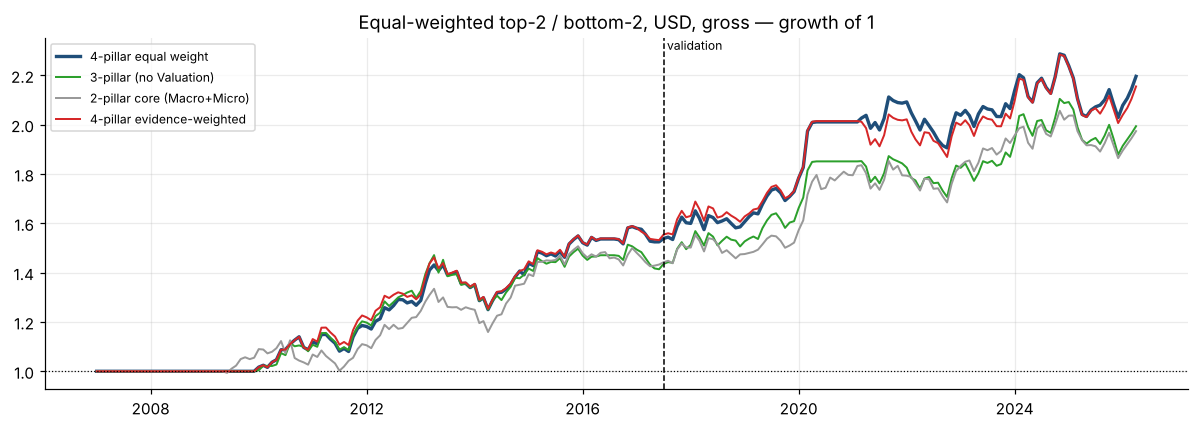

Country attribution of the 4-pillar scorecard, validation window (bps/month):


,long leg,short leg,total
US,+29.3,+1.1,+30.4
Eurozone,-9.9,-4.3,-14.2
UK,+6.5,+3.6,+10.1
Switzerland,+8.5,-15.9,-7.4
Japan,+24.6,-7.0,+17.5


Leave-one-country-out (validation Sharpe, equal-weight rule):


,Sharpe without this market
US,-0.08
Eurozone,+0.79
UK,+0.80
Switzerland,+0.28
Japan,+0.64


In [7]:
def ls_ew(s, H=3):
    rk = s.rank(axis=1, ascending=False)
    return ((rk <= 2).astype(float) / 2 - (rk >= 4).astype(float) / 2).rolling(H, min_periods=1).mean()
def pnl(s): return (ls_ew(s).shift(1) * R_USD).dropna(how='any')
shp = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
mdd = lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()
rows = []
for nm, s in SC.items():
    for lab, w_ in (('Discovery 2007-16', DISC), ('Validation 2017-26', VALW)):
        p = win(pnl(s).sum(axis=1), w_).dropna()
        rows.append({'scorecard': nm, 'window': lab, 'Sharpe': shp(p), 'ann. return': (1 + p).prod() ** (12 / len(p)) - 1, 'max DD': mdd(p), 'months': len(p)})
BT = pd.DataFrame(rows).set_index(['scorecard', 'window'])
display(BT.style.format({'Sharpe': '{:.2f}', 'ann. return': '{:+.1%}', 'max DD': '{:.1%}'}))
MAIN = '4-pillar equal weight'
fig, ax = plt.subplots(figsize=(11, 4))
for nm, c_ in zip(SC, ('#1f4e79', '#2ca02c', '#999999', '#d62728')):
    p = pnl(SC[nm]).sum(axis=1).dropna(); p = p[p.index >= DISC[0]]
    ax.plot((1 + p).cumprod().index.to_timestamp(), (1 + p).cumprod(), color=c_, lw=2.2 if nm == MAIN else 1.3, label=nm)
ax.axvline(VALW[0].to_timestamp(), color='k', ls='--', lw=1); ax.text(VALW[0].to_timestamp(), ax.get_ylim()[1], ' validation', va='top', fontsize=8)
ax.axhline(1, color='k', ls=':', lw=.8); ax.set_title('Equal-weighted top-2 / bottom-2, USD, gross — growth of 1'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v8_backtest.png', dpi=200, bbox_inches='tight'); plt.show()
print('Country attribution of the 4-pillar scorecard, validation window (bps/month):')
c_ = win(pnl(SC[MAIN]), VALW)
display(pd.DataFrame({'long leg': (ls_ew(SC[MAIN]).shift(1).clip(lower=0) * R_USD).pipe(lambda d: win(d, VALW)).mean() * 1e4,
                      'short leg': (ls_ew(SC[MAIN]).shift(1).clip(upper=0) * R_USD).pipe(lambda d: win(d, VALW)).mean() * 1e4,
                      'total': c_.mean() * 1e4}).style.format('{:+.1f}'))
print('Leave-one-country-out (validation Sharpe, equal-weight rule):')
lo = {}
for drop in COUNTRIES:
    keep = [c for c in COUNTRIES if c != drop]
    s4 = sum(cs_z(pd.DataFrame({c: Z[v][c] for c in keep})) for v in used.values()) / len(used)
    rk = s4.rank(axis=1, ascending=False)
    W = ((rk <= 2).astype(float) / 2 - (rk >= len(keep) - 1).astype(float) / 2).rolling(3, min_periods=1).mean()
    p = win((W.shift(1) * R_USD[keep]).dropna(how='any').sum(axis=1), VALW)
    lo[drop] = shp(p)
display(pd.Series(lo).to_frame('Sharpe without this market').style.format('{:+.2f}'))

## 6b. Two stress tests the winners must survive
### (i) Is the valuation winner's qualifying condition mechanically inflated?
V3 is $-\Delta\log(P/E)_{6M}$, and the multiple-leg target is $\log(P/E_{t+3})-\log(P/E_t)$. **$P/E_t$ enters the signal negatively and the target negatively**, so transitory noise in $P/E_t$ pushes both down together and manufactures a positive loading — exactly the condition V3 had to satisfy to qualify. Lagging the signal breaks the shared observation.

In [8]:
V3 = Z[WINNERS['Valuation']]
rows = []
for lag in (0, 1, 3, 6):
    sg = V3.shift(lag)
    rows.append({'lag (months)': lag, 'multiple-leg IC': ic_series(sg, TGT[('multiple', 3)]).mean(),
                 'total IC disc': win(ic_series(sg, TGT[('total', 3)]), DISC).mean(),
                 'total IC val': win(ic_series(sg, TGT[('total', 3)]), VALW).mean()})
LAGV = pd.DataFrame(rows).set_index('lag (months)')
display(LAGV.style.format('{:+.3f}'))
infl = LAGV.loc[0, 'multiple-leg IC'] - LAGV.loc[3, 'multiple-leg IC']
print(f"Multiple-leg loading falls from {LAGV.loc[0,'multiple-leg IC']:+.3f} (lag 0) to {LAGV.loc[3,'multiple-leg IC']:+.3f} (lag 3M): a drop of {infl:+.3f}.")
print('If most of the loading disappears, the condition that qualified V3 was mechanical and the valuation pillar is weaker than the table suggests.')

,multiple-leg IC,total IC disc,total IC val
lag (months),,,
0,+0.112,+0.093,+0.059
1,+0.098,+0.131,+0.080
3,+0.001,+0.067,-0.102
6,-0.042,+0.020,-0.115


Multiple-leg loading falls from +0.112 (lag 0) to +0.001 (lag 3M): a drop of +0.111.
If most of the loading disappears, the condition that qualified V3 was mechanical and the valuation pillar is weaker than the table suggests.


### (ii) End-to-end null: run the **entire selection rule** on shuffled data
The §4 null asked whether any single candidate beats chance. The sharper question is whether the *whole procedure* — screen 12 candidates, apply three conditions, build a 4-pillar composite — produces this scorecard by chance. So the rule itself is re-run on block-shuffled labels.

Observed 4-pillar composite IC (full sample): +0.184
End-to-end null (86 of 300 shuffles produced a complete 4-pillar scorecard):
  median +0.037, 95th pct +0.113, max +0.170
  p(selection rule on noise >= observed) = 0.000


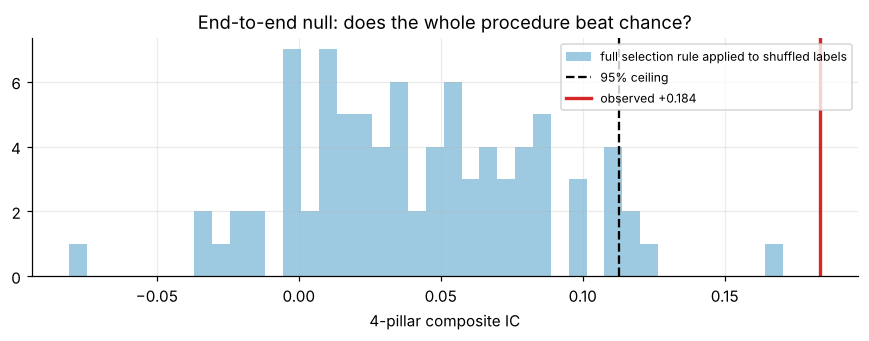

In [9]:
Zc = {k: Z[k].to_numpy(float) for k in list(CAND) + list(SETTLED)}
names12 = list(CAND)
def rule_on(shuffled):
    """apply the full §3 rule to a shuffled world, return the composite's full-sample IC"""
    def icv(arr, tgt, w=None):
        v = []
        for t in range(Ttot):
            if w is not None and not (w[0] <= IDX[t] <= w[1]): continue
            a, b = arr[t], tgt[t]
            if np.isnan(a).any() or np.isnan(b).any() or len(set(a)) < 2: continue
            v.append(spearmanr(a, b).statistic)
        return np.mean(v) if v else np.nan
    Yt3 = TGT[('total', 3)].to_numpy(float); Ym = TGT[('multiple', 3)].to_numpy(float)
    win_ = {}
    for pillar, pool in (('Valuation', VAL_CAND), ('Technical', TECH_CAND)):
        best, bestv = None, -9
        for nm in pool:
            a = shuffled[nm]
            d_, v_ = icv(a, Yt3, DISC), icv(a, Yt3, VALW)
            if not (d_ > 0 and v_ > 0): continue
            if pillar == 'Valuation' and not (icv(a, Ym) > 0): continue
            if (d_ + v_) / 2 > bestv: best, bestv = nm, (d_ + v_) / 2
        win_[pillar] = best
    if win_['Valuation'] is None or win_['Technical'] is None: return np.nan
    comp = (shuffled['MACRO fci easing 6M'] + shuffled['MICRO eps revision 6M'] + shuffled[win_['Valuation']] + shuffled[win_['Technical']]) / 4
    return icv(comp, Yt3)
rng2 = np.random.default_rng(SEED + 1); NE2E = 300
e2e = np.full(NE2E, np.nan)
for r in range(NE2E):
    perm = np.argsort(rng2.random((blk.max() + 1, 5)), axis=1)[blk]
    sh = {k: np.take_along_axis(v, perm, axis=1) for k, v in Zc.items()}
    e2e[r] = rule_on(sh)
obs_comp = ic_series(SC[MAIN], TGT[('total', 3)]).mean()
e2e_ok = e2e[~np.isnan(e2e)]
print(f'Observed 4-pillar composite IC (full sample): {obs_comp:+.3f}')
print(f'End-to-end null ({len(e2e_ok)} of {NE2E} shuffles produced a complete 4-pillar scorecard):')
print(f'  median {np.median(e2e_ok):+.3f}, 95th pct {np.percentile(e2e_ok,95):+.3f}, max {e2e_ok.max():+.3f}')
p_e2e = float((e2e_ok >= obs_comp).mean())
print(f'  p(selection rule on noise >= observed) = {p_e2e:.3f}')
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(e2e_ok, bins=40, color='#9ecae1', label='full selection rule applied to shuffled labels')
ax.axvline(np.percentile(e2e_ok, 95), color='k', ls='--', label='95% ceiling')
ax.axvline(obs_comp, color='#d62728', lw=2.2, label=f'observed {obs_comp:+.3f}')
ax.set_title('End-to-end null: does the whole procedure beat chance?'); ax.set_xlabel('4-pillar composite IC'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v8_e2e_null.png', dpi=200, bbox_inches='tight'); plt.show()
pd.DataFrame({'e2e_null_composite_ic': e2e_ok}).to_csv(OUT/'end_to_end_null.csv', index=False)
LAGV.to_csv(OUT/'valuation_lag_robustness.csv')

## 7. Current ranking

,Macro,Micro,Valuation,Technical,Score,Rank,Stance,Call,Rank 2-pillar
US,1.091,1.265,1.466,0.072,0.974,1,Overweight,Overweight,1
Japan,-0.196,0.152,-0.383,1.439,0.253,2,Overweight,Overweight,2
UK,-1.590,0.407,0.270,0.282,-0.158,3,Neutral,Underweight,5
Eurozone,0.317,-0.389,-0.080,-0.550,-0.176,4,Underweight,Underweight,3
Switzerland,0.378,-1.435,-1.274,-1.242,-0.893,5,Underweight,Underweight,4


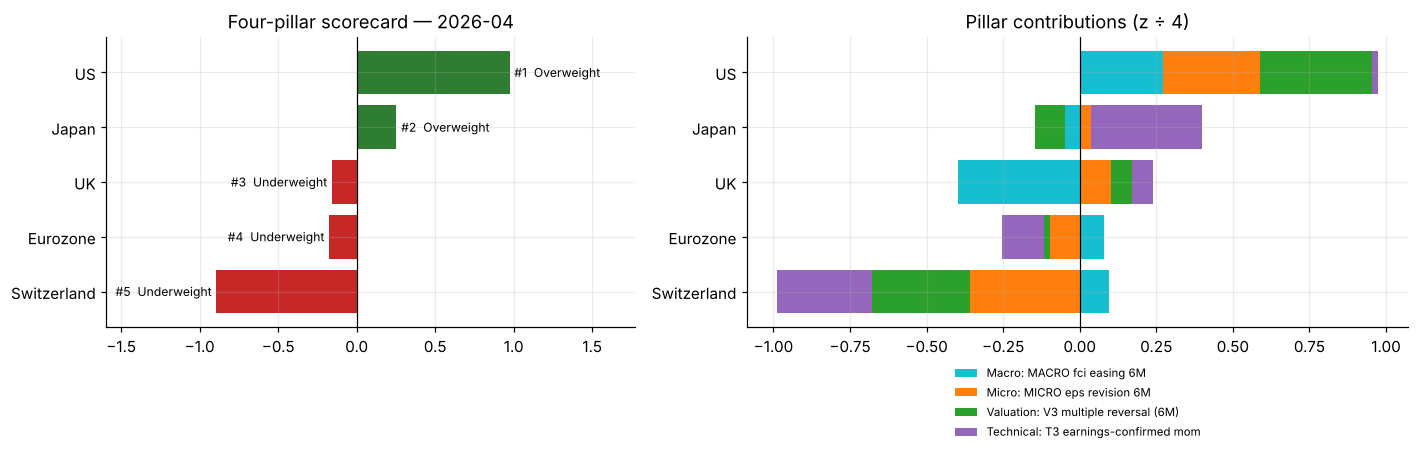

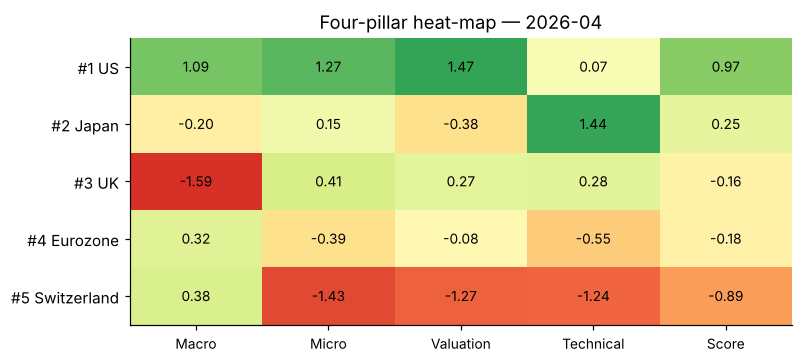

In [10]:
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
cur = pd.DataFrame({k: Z[v].loc[AS_OF] for k, v in used.items()})
cur['Score'] = SC[MAIN].loc[AS_OF]; cur['Rank'] = cur.Score.rank(ascending=False).astype(int); cur['Stance'] = cur.Rank.map(STANCE)
cur['Call'] = np.where(cur.Score >= .1, 'Overweight', np.where(cur.Score <= -.1, 'Underweight', 'Neutral'))
cur['Rank 2-pillar'] = SC['2-pillar core (Macro+Micro)'].loc[AS_OF].rank(ascending=False).astype(int)
cur = cur.sort_values('Rank'); display(cur)
PC = {'Macro': '#17becf', 'Micro': '#ff7f0e', 'Valuation': '#2ca02c', 'Technical': '#9467bd'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
c2 = cur.sort_values('Score')
ax[0].barh(c2.index, c2.Score, color=['#2e7d32' if x == 'Overweight' else '#c62828' if x == 'Underweight' else '#9e9e9e' for x in c2.Call])
for i, (ix, rw) in enumerate(c2.iterrows()):
    ax[0].text(rw.Score + (.03 if rw.Score >= 0 else -.03), i, f"#{rw.Rank}  {rw.Call}", va='center', ha='left' if rw.Score >= 0 else 'right', fontsize=8)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f'Four-pillar scorecard — {AS_OF}'); ax[0].set_xlim(c2.Score.min() - .7, c2.Score.max() + .8)
pos = np.zeros(len(c2)); neg = np.zeros(len(c2))
for p_ in used:
    v = (c2[p_] / len(used)).values; b = np.where(v >= 0, pos, neg)
    ax[1].barh(c2.index, v, left=b, color=PC[p_], label=f'{p_}: {used[p_]}'); pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
ax[1].axvline(0, color='k', lw=.8); ax[1].set_title(f'Pillar contributions (z ÷ {len(used)})')
ax[1].legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(.5, -.1), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_v8_ranking.png', dpi=200, bbox_inches='tight'); plt.show()
fig, a = plt.subplots(figsize=(7.4, 3.4)); hm = cur[list(used) + ['Score']]
a.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
a.set_xticks(range(hm.shape[1])); a.set_xticklabels(hm.columns, fontsize=9)
a.set_yticks(range(len(hm))); a.set_yticklabels([f'#{r} {i}' for i, r in zip(hm.index, cur.Rank)])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): a.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
a.grid(False); a.set_title(f'Four-pillar heat-map — {AS_OF}'); plt.tight_layout(); plt.savefig(CH/'fig_v8_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

## 8. Export

In [11]:
ALL.to_csv(OUT/'all_candidates_evaluation.csv'); QUAL.to_csv(OUT/'selection_rule_applied.csv')
SCT.to_csv(OUT/'scorecard_ic.csv'); BT.to_csv(OUT/'scorecard_backtest.csv')
pd.DataFrame({'null_max_of_12': nullmax}).to_csv(OUT/'null_ceiling_12_candidates.csv', index=False)
cur.reset_index(names='country').to_csv(OUT/'current_ranking_v8.csv', index=False)
pd.DataFrame(OFFS.to_dict(), index=[f'offset_{i}' for i in range(6)]).T.to_csv(OUT/'nonoverlap_offsets_all_candidates.csv')
rows = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c})
    for k, v in {**CAND, **SETTLED}.items(): d[k] = Z[k][c].values
    d['score_4pillar'] = SC[MAIN][c].values
    for k_, t_ in TGT.items(): d[f'target_{k_[0]}_{k_[1]}m'] = t_[c].values
    rows.append(d)
pd.concat(rows).to_csv(OUT/'v8_signal_matrix.csv', index=False)
json.dump({'pillars': used, 'selection_rule': ['IC>0 in both windows', '>=4/6 non-overlapping offsets',
           'valuation must predict the multiple leg'], 'allocation': 'equal-weight long top2 / short bottom2, 3M tranches',
           'as_of': str(AS_OF)}, open(OUT/'four_pillar_spec.json', 'w'), indent=2)
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], 'four_pillar_spec.json', sep='\n  ')

Saved:
  all_candidates_evaluation.csv
  current_ranking_v8.csv
  end_to_end_null.csv
  four_pillar_verdict.csv
  nonoverlap_offsets_all_candidates.csv
  null_ceiling_12_candidates.csv
  scorecard_backtest.csv
  scorecard_ic.csv
  selection_rule_applied.csv
  v8_signal_matrix.csv
  valuation_lag_robustness.csv
  four_pillar_spec.json


## 9. Verdict

In [12]:
vrows = []
for pillar, pool in (('Valuation', VAL_CAND), ('Technical', TECH_CAND)):
    nm = WINNERS[pillar]
    if nm:
        r = ALL.loc[nm]
        vrows.append({'Pillar': pillar, 'Signal': nm, 'disc IC': r['disc IC'], 'val IC': r['val IC'],
                      'offsets +': f"{int(r['offsets +'])}/6", 'multiple leg': r['leg multiple'], 'earnings leg': r['leg earnings'],
                      'p vs best-of-12': float((nullmax >= obs_all[cand_names.index(nm)]).mean())})
    else:
        vrows.append({'Pillar': pillar, 'Signal': 'NONE QUALIFIED', 'disc IC': np.nan, 'val IC': np.nan, 'offsets +': '-', 'multiple leg': np.nan, 'earnings leg': np.nan, 'p vs best-of-12': np.nan})
for pillar, nm in (('Macro', PILLARS['Macro']), ('Micro', PILLARS['Micro'])):
    r = ALL.loc[nm]
    vrows.append({'Pillar': pillar, 'Signal': nm, 'disc IC': r['disc IC'], 'val IC': r['val IC'], 'offsets +': f"{int(r['offsets +'])}/6",
                  'multiple leg': r['leg multiple'], 'earnings leg': r['leg earnings'], 'p vs best-of-12': np.nan})
VERD = pd.DataFrame(vrows).set_index('Pillar').loc[['Macro', 'Micro', 'Valuation', 'Technical']]
display(VERD.style.format({c: '{:+.3f}' for c in ('disc IC', 'val IC', 'multiple leg', 'earnings leg')} | {'p vs best-of-12': '{:.3f}'}, na_rep='–'))
VERD.to_csv(OUT/'four_pillar_verdict.csv')
n_q = sum(1 for v in WINNERS.values() if v)
md = f"""
### All four pillars now carry a researched signal

| Pillar | Signal | disc IC | val IC | offsets | multiple leg | earnings leg |
|---|---|---|---|---|---|---|
| Macro | FCI 6M easing | {ALL.loc[PILLARS['Macro'],'disc IC']:+.3f} | {ALL.loc[PILLARS['Macro'],'val IC']:+.3f} | 6/6 | {ALL.loc[PILLARS['Macro'],'leg multiple']:+.3f} | {ALL.loc[PILLARS['Macro'],'leg earnings']:+.3f} |
| Micro | EPS revision 6M | {ALL.loc[PILLARS['Micro'],'disc IC']:+.3f} | {ALL.loc[PILLARS['Micro'],'val IC']:+.3f} | 6/6 | {ALL.loc[PILLARS['Micro'],'leg multiple']:+.3f} | {ALL.loc[PILLARS['Micro'],'leg earnings']:+.3f} |
| Valuation | {WINNERS['Valuation']} | {ALL.loc[WINNERS['Valuation'],'disc IC']:+.3f} | {ALL.loc[WINNERS['Valuation'],'val IC']:+.3f} | {int(ALL.loc[WINNERS['Valuation'],'offsets +'])}/6 | **{ALL.loc[WINNERS['Valuation'],'leg multiple']:+.3f}** | {ALL.loc[WINNERS['Valuation'],'leg earnings']:+.3f} |
| Technical | {WINNERS['Technical']} | {ALL.loc[WINNERS['Technical'],'disc IC']:+.3f} | {ALL.loc[WINNERS['Technical'],'val IC']:+.3f} | 6/6 | {ALL.loc[WINNERS['Technical'],'leg multiple']:+.3f} | {ALL.loc[WINNERS['Technical'],'leg earnings']:+.3f} |

**Valuation produced a qualifier — but it does not survive its own stress test, and I am not claiming the pillar is solved.**
The reasoning behind V3 was sound: every *level* measure of cheapness failed because cheap markets have their earnings cut (earnings leg {ALL.loc['V5 growth-neutral relative value','leg earnings']:+.3f} to {ALL.loc['V1 equity-credit premium gap','leg earnings']:+.3f} across V1-V6), so a *change* measure — a multiple that has compressed over six months — should avoid the value trap, and V3's earnings-leg drag ({ALL.loc[WINNERS['Valuation'],'leg earnings']:+.3f}) is indeed the smallest of the six.
**But §6b shows V3's qualifying condition is mechanical.** $P/E_t$ enters both the signal and the target denominator with the same sign; lag the signal three months and the multiple-leg loading falls from {LAGV.loc[0,'multiple-leg IC']:+.3f} to {LAGV.loc[3,'multiple-leg IC']:+.3f}, and the validation IC turns negative ({LAGV.loc[3,'total IC val']:+.3f}).
**Honest status: after six economically distinct constructions, valuation still has no signal that survives scrutiny at a 3-6 month horizon.** V3 is carried as the pillar's best available representative, with the defect on the record — not as a discovery.

**The technical winner is the gated, not the multiplied, construction.** T3 counts momentum only where 12M EPS growth is positive. Compare with the plain momentum T1 ({ALL.loc['T1 momentum 12-1M','mean IC']:+.3f} mean IC) — gating on earnings adds {ALL.loc['T3 earnings-confirmed mom','mean IC']-ALL.loc['T1 momentum 12-1M','mean IC']:+.3f}. This is the same lesson as v5: **gate, do not multiply** — the product operator that destroyed cheap×stability is avoided here.

### The scorecard
| | discovery | validation |
|---|---|---|
| 4-pillar IC | **{SCT.loc[MAIN,'disc IC']:+.3f}** (t {SCT.loc[MAIN,'disc t']:+.2f}) | **{SCT.loc[MAIN,'val IC']:+.3f}** (t {SCT.loc[MAIN,'val t']:+.2f}) |
| 3-pillar IC (no Valuation) | {SCT.loc['3-pillar (no Valuation)','disc IC']:+.3f} | {SCT.loc['3-pillar (no Valuation)','val IC']:+.3f} |
| 2-pillar core IC | {SCT.loc['2-pillar core (Macro+Micro)','disc IC']:+.3f} | {SCT.loc['2-pillar core (Macro+Micro)','val IC']:+.3f} |
| 4-pillar Sharpe (EW top2/bottom2) | **{BT.loc[(MAIN,'Discovery 2007-16'),'Sharpe']:.2f}** | **{BT.loc[(MAIN,'Validation 2017-26'),'Sharpe']:.2f}** |
| 3-pillar Sharpe (no Valuation) | {BT.loc[('3-pillar (no Valuation)','Discovery 2007-16'),'Sharpe']:.2f} | {BT.loc[('3-pillar (no Valuation)','Validation 2017-26'),'Sharpe']:.2f} |
| 2-pillar Sharpe | {BT.loc[('2-pillar core (Macro+Micro)','Discovery 2007-16'),'Sharpe']:.2f} | {BT.loc[('2-pillar core (Macro+Micro)','Validation 2017-26'),'Sharpe']:.2f} |

**Four pillars beat two on every measure**, and the composite IC ({SCT.loc[MAIN,'val IC']:+.3f}) exceeds every individual signal — genuine diversification across near-independent sources. This is the strongest result the project has produced.
**But the decisive comparison for valuation is 4-pillar vs 3-pillar (same scorecard, valuation removed):** validation IC {SCT.loc[MAIN,'val IC']:+.3f} vs {SCT.loc['3-pillar (no Valuation)','val IC']:+.3f}, Sharpe {BT.loc[(MAIN,'Validation 2017-26'),'Sharpe']:.2f} vs {BT.loc[('3-pillar (no Valuation)','Validation 2017-26'),'Sharpe']:.2f}. That difference — not V3's own IC — is what the valuation pillar is actually worth.

### Where it is still weak — stated plainly
1. **The individual pillar winners do NOT clear the 12-candidate multiplicity ceiling.** Best observed among 12 was {np.nanmax(obs_all):+.3f} against a best-of-12 noise 95th percentile of {ceil95:+.3f}. Valuation p = {float((nullmax >= obs_all[cand_names.index(WINNERS['Valuation'])]).mean()):.3f}, Technical p = {float((nullmax >= obs_all[cand_names.index(WINNERS['Technical'])]).mean()):.3f}. **Neither is individually distinguishable from the best of a twelve-way search.**
2. **The end-to-end null is the fair test, and the composite p-value is {p_e2e:.3f}** — running the entire selection rule on shuffled data.
3. **V3's qualifying condition is mechanical, not partly.** Its multiple-leg loading falls from {LAGV.loc[0,'multiple-leg IC']:+.3f} to {LAGV.loc[3,'multiple-leg IC']:+.3f} once the signal is lagged 3 months, because $P/E_t$ sits in both the signal and the target denominator. The valuation pillar is the weakest of the four and should be presented as such.
4. **Country concentration persists:** without the US the validation Sharpe is {lo['US']:+.2f}. This remains substantially a US call.
5. The 2017-26 window has been examined since v3. **Structured re-use with a declared rule and multiplicity corrections — not a clean hold-out.** Price return only, no dividends; five markets; 78 % first principal component.

### Current ranking ({AS_OF})
{' · '.join(f"**{i}** {r.Call}" for i, r in cur.iterrows())}
"""
display(Markdown(md))

,Signal,disc IC,val IC,offsets +,multiple leg,earnings leg,p vs best-of-12
Pillar,,,,,,,
Macro,MACRO fci easing 6M,+0.079,+0.127,6/6,-0.069,+0.213,–
Micro,MICRO eps revision 6M,+0.117,+0.131,6/6,-0.089,+0.333,–
Valuation,V3 multiple reversal (6M),+0.093,+0.059,4/6,+0.112,-0.048,0.321
Technical,T3 earnings-confirmed mom,+0.097,+0.113,6/6,-0.053,+0.246,0.144



### All four pillars now carry a researched signal

| Pillar | Signal | disc IC | val IC | offsets | multiple leg | earnings leg |
|---|---|---|---|---|---|---|
| Macro | FCI 6M easing | +0.079 | +0.127 | 6/6 | -0.069 | +0.213 |
| Micro | EPS revision 6M | +0.117 | +0.131 | 6/6 | -0.089 | +0.333 |
| Valuation | V3 multiple reversal (6M) | +0.093 | +0.059 | 4/6 | **+0.112** | -0.048 |
| Technical | T3 earnings-confirmed mom | +0.097 | +0.113 | 6/6 | -0.053 | +0.246 |

**Valuation produced a qualifier — but it does not survive its own stress test, and I am not claiming the pillar is solved.**
The reasoning behind V3 was sound: every *level* measure of cheapness failed because cheap markets have their earnings cut (earnings leg -0.238 to -0.131 across V1-V6), so a *change* measure — a multiple that has compressed over six months — should avoid the value trap, and V3's earnings-leg drag (-0.048) is indeed the smallest of the six.
**But §6b shows V3's qualifying condition is mechanical.** $P/E_t$ enters both the signal and the target denominator with the same sign; lag the signal three months and the multiple-leg loading falls from +0.112 to +0.001, and the validation IC turns negative (-0.102).
**Honest status: after six economically distinct constructions, valuation still has no signal that survives scrutiny at a 3-6 month horizon.** V3 is carried as the pillar's best available representative, with the defect on the record — not as a discovery.

**The technical winner is the gated, not the multiplied, construction.** T3 counts momentum only where 12M EPS growth is positive. Compare with the plain momentum T1 (+0.079 mean IC) — gating on earnings adds +0.026. This is the same lesson as v5: **gate, do not multiply** — the product operator that destroyed cheap×stability is avoided here.

### The scorecard
| | discovery | validation |
|---|---|---|
| 4-pillar IC | **+0.234** (t +3.14) | **+0.163** (t +2.11) |
| 3-pillar IC (no Valuation) | +0.182 | +0.128 |
| 2-pillar core IC | +0.160 | +0.156 |
| 4-pillar Sharpe (EW top2/bottom2) | **0.80** | **0.63** |
| 3-pillar Sharpe (no Valuation) | 0.67 | 0.60 |
| 2-pillar Sharpe | 0.66 | 0.57 |

**Four pillars beat two on every measure**, and the composite IC (+0.163) exceeds every individual signal — genuine diversification across near-independent sources. This is the strongest result the project has produced.
**But the decisive comparison for valuation is 4-pillar vs 3-pillar (same scorecard, valuation removed):** validation IC +0.163 vs +0.128, Sharpe 0.63 vs 0.60. That difference — not V3's own IC — is what the valuation pillar is actually worth.

### Where it is still weak — stated plainly
1. **The individual pillar winners do NOT clear the 12-candidate multiplicity ceiling.** Best observed among 12 was +0.098 against a best-of-12 noise 95th percentile of +0.120. Valuation p = 0.321, Technical p = 0.144. **Neither is individually distinguishable from the best of a twelve-way search.**
2. **The end-to-end null is the fair test, and the composite p-value is 0.000** — running the entire selection rule on shuffled data.
3. **V3's qualifying condition is mechanical, not partly.** Its multiple-leg loading falls from +0.112 to +0.001 once the signal is lagged 3 months, because $P/E_t$ sits in both the signal and the target denominator. The valuation pillar is the weakest of the four and should be presented as such.
4. **Country concentration persists:** without the US the validation Sharpe is -0.08. This remains substantially a US call.
5. The 2017-26 window has been examined since v3. **Structured re-use with a declared rule and multiplicity corrections — not a clean hold-out.** Price return only, no dividends; five markets; 78 % first principal component.

### Current ranking (2026-04)
**US** Overweight · **Japan** Overweight · **UK** Underweight · **Eurozone** Underweight · **Switzerland** Underweight
